In [1]:
# Setup: imports and seed
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

np.random.seed(0)

In [2]:
# Data: fetch KDD Cup 99 (10% version)
kdd = fetch_kddcup99(subset=None, as_frame=True)
data = kdd.data
target = kdd.target
print(data.shape)

(494021, 41)


In [3]:
# Data: decode text columns and convert other columns to float
text_cols = ["protocol_type", "service", "flag"]

for col in text_cols:
    data[col] = data[col].str.decode("utf-8")

other_cols = []
for col in data.columns:
    if col not in text_cols:
        other_cols.append(col)

for col in other_cols:
    data[col] = data[col].astype(float)

C:\Users\RAHUL GUPTA\AppData\Local\Temp\ipykernel_40064\2683317220.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].str.decode("utf-8")
C:\Users\RAHUL GUPTA\AppData\Local\Temp\ipykernel_40064\2683317220.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col] = data[col].astype(float)
C:\Users\RAHUL GUPTA\AppData\Local\Temp\ipykernel_40064\2683317220.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,co

In [4]:
# Data: one-hot encode the three text columns
data = pd.get_dummies(data, columns=text_cols, dtype=float)
print(data.shape)

(494021, 118)


In [5]:
# Data: drop columns that have the same value in every row
keep_cols = []
for col in data.columns:
    if data[col].nunique() > 1:
        keep_cols.append(col)

data = data[keep_cols]
print(data.shape)

(494021, 116)


In [6]:
# Data: rescale each column to [0,1] and report n and d
D = data.to_numpy(dtype=np.float32)

col_min = D.min(axis=0)
col_max = D.max(axis=0)
D = (D - col_min) / (col_max - col_min)

n = D.shape[0]
d = D.shape[1]
print("n =", n)
print("d =", d)

n = 494021
d = 116


In [7]:
# Q1 helpers: cost(D, B) and cost of a partition
k = 15

def get_cost(D, B):
    B = B.astype(np.float32)
    best = np.full(D.shape[0], np.inf)
    for j in range(B.shape[0]):
        diff = D - B[j]
        dist = (diff * diff).sum(axis=1)
        dist = dist.astype(np.float64)
        for_update = dist < best
        best[for_update] = dist[for_update]
    return best.sum()


def partition_cost(X, labels, k):
    total = 0.0
    for j in range(k):
        rows = X[labels == j]
        rows = rows.astype(np.float64)
        centre = rows.mean(axis=0)
        diff = rows - centre
        total = total + (diff * diff).sum()
    return total

In [8]:
# Q1(a): k-means on D, report cost and time
start = time.time()
km = KMeans(n_clusters=15, n_init=5, random_state=0)
km.fit(D)
end = time.time()

time_a = end - start
B = km.cluster_centers_
labels_D = km.labels_
cost_B = get_cost(D, B)

print("cost(D, B) =", cost_B)
print("time =", time_a, "seconds")

c:\Users\RAHUL GUPTA\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\RAHUL GUPTA\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\RAHUL GUPTA\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\RAHUL GUPTA\AppData\Local\Programs\Python\Python3

cost(D, B) = 52711.69547021693
time = 21.749794960021973 seconds


In [9]:
# Q1(b),(c),(d): random projection runs, B_hat and B_plus costs, and times
m_list = [5, 10, 15, 20, 25]
results = []

for m in m_list:
    for run in range(5):
        np.random.seed(1000 * m + run)

        A = np.random.normal(0, 1 / np.sqrt(m), size=(m, d))
        A = A.astype(np.float32)

        start = time.time()
        E = D @ A.T
        km_E = KMeans(n_clusters=15, n_init=5, random_state=run)
        km_E.fit(E)
        end = time.time()
        time_E = end - start

        labels_E = km_E.labels_
        centres_E = km_E.cluster_centers_

        # B_hat: average the original rows of each cluster
        B_hat = np.zeros((k, d))
        for j in range(k):
            rows = D[labels_E == j]
            B_hat[j] = rows.mean(axis=0)

        # B_plus: map centres back with pseudo-inverse
        A_pinv = np.linalg.pinv(A.astype(np.float64))
        B_plus = centres_E @ A_pinv.T

        cost_hat = get_cost(D, B_hat)
        cost_plus = get_cost(D, B_plus)

        row = {}
        row["m"] = m
        row["run"] = run
        row["cost_hat"] = cost_hat
        row["ratio_hat"] = cost_hat / cost_B
        row["cost_plus"] = cost_plus
        row["ratio_plus"] = cost_plus / cost_B
        row["time"] = time_E
        results.append(row)

        print(m, run, row["ratio_hat"], row["ratio_plus"])

5 0 1.1992693086852781 81.42954503220847
5 1 1.2097196895815787 79.0214316708795
5 2 1.1858503134472231 80.91798903278324
5 3 1.363500212356775 79.90732593097493
5 4 1.9305115407063178 81.7818879427077
10 0 0.9890841044679611 76.42271299112834
10 1 1.0121879660141337 77.9635547653483
10 2 1.1856709352295027 78.27914316401508
10 3 1.1150814266350344 76.88262578341404
10 4 1.0349119987706221 78.04805274000529
15 0 1.0311374639546989 73.39705051162356
15 1 1.1083264352685889 72.92084119557819
15 2 1.0740261911828457 72.72930686359595
15 3 1.0694651654126341 78.02727099925181
15 4 1.0502073773132974 73.57382949399052
20 0 1.0203680056048576 64.7529317179645
20 1 1.0152481029174143 69.84320956072894
20 2 1.046099034641444 67.32887892663004
20 3 1.0664868251467468 72.34858560286298
20 4 0.9877282707525862 72.27570084642502
25 0 1.0422177927552034 66.06354336022176
25 1 1.0424959200489785 67.76971854451023
25 2 1.0480403408883774 70.0774954927601
25 3 0.9996601220949617 64.78835558027063
25 4

In [10]:
# Q1(b): all 25 runs, cost and ratio for B_hat
all_runs = pd.DataFrame(results)
print(all_runs[["m", "run", "cost_hat", "ratio_hat"]])

     m  run       cost_hat  ratio_hat
0    5    0   63215.518586   1.199269
1    5    1   63766.375882   1.209720
2    5    2   62508.180596   1.185850
3    5    3   71872.407967   1.363500
4    5    4  101760.536435   1.930512
5   10    0   52136.300109   0.989084
6   10    1   53354.143823   1.012188
7   10    2   62498.725266   1.185671
8   10    3   58777.832585   1.115081
9   10    4   54551.966118   1.034912
10  15    0   54353.003988   1.031137
11  15    1   58421.765537   1.108326
12  15    2   56613.741517   1.074026
13  15    3   56373.322115   1.069465
14  15    4   55358.211454   1.050207
15  20    0   53785.327579   1.020368
16  20    1   53515.448828   1.015248
17  20    2   55141.653746   1.046099
18  20    3   56216.328750   1.066487
19  20    4   52064.831815   0.987728
20  25    0   54937.066905   1.042218
21  25    1   54951.727467   1.042496
22  25    2   55243.983289   1.048040
23  25    3   52693.779930   0.999660
24  25    4   54555.441534   1.034978


In [11]:
# Q1(b): mean, smallest and largest ratio per m (table)
table_rows = []

for m in m_list:
    ratios = []
    for row in results:
        if row["m"] == m:
            ratios.append(row["ratio_hat"])

    t = {}
    t["m"] = m
    t["mean"] = np.mean(ratios)
    t["min"] = np.min(ratios)
    t["max"] = np.max(ratios)
    table_rows.append(t)

table_b = pd.DataFrame(table_rows)
print(table_b)

    m      mean       min       max
0   5  1.377770  1.185850  1.930512
1  10  1.067387  0.989084  1.185671
2  15  1.066633  1.031137  1.108326
3  20  1.027186  0.987728  1.066487
4  25  1.033478  0.999660  1.048040


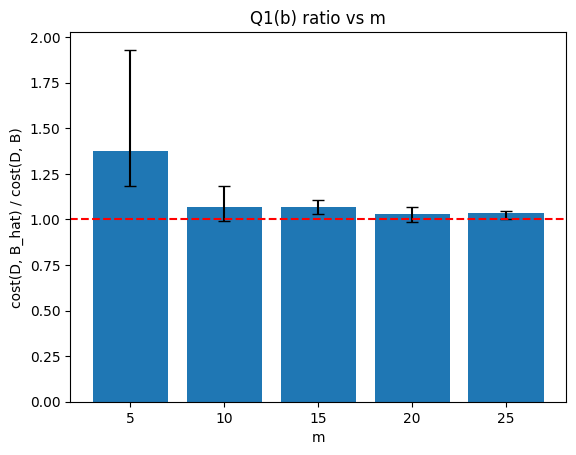

In [12]:
# Q1(b): bar graph of mean ratio with min and max
means = []
lower = []
upper = []

for t in table_rows:
    means.append(t["mean"])
    lower.append(t["mean"] - t["min"])
    upper.append(t["max"] - t["mean"])

positions = range(len(m_list))
plt.bar(positions, means, yerr=[lower, upper], capsize=4)
plt.xticks(positions, m_list)
plt.axhline(1.0, color="red", linestyle="--")
plt.xlabel("m")
plt.ylabel("cost(D, B_hat) / cost(D, B)")
plt.title("Q1(b) ratio vs m")
plt.show()

In [13]:
# Q1(c): ratio of B_plus next to ratio of B_hat
table_rows_c = []

for m in m_list:
    ratios_hat = []
    ratios_plus = []
    for row in results:
        if row["m"] == m:
            ratios_hat.append(row["ratio_hat"])
            ratios_plus.append(row["ratio_plus"])

    t = {}
    t["m"] = m
    t["B_hat mean"] = np.mean(ratios_hat)
    t["B_plus mean"] = np.mean(ratios_plus)
    t["B_plus min"] = np.min(ratios_plus)
    t["B_plus max"] = np.max(ratios_plus)
    table_rows_c.append(t)

table_c = pd.DataFrame(table_rows_c)
print(table_c)

    m  B_hat mean  B_plus mean  B_plus min  B_plus max
0   5    1.377770    80.611636   79.021432   81.781888
1  10    1.067387    77.519218   76.422713   78.279143
2  15    1.066633    74.129660   72.729307   78.027271
3  20    1.027186    69.309861   64.752932   72.348586
4  25    1.033478    66.540202   64.001899   70.077495


[np.float64(3.1042919635772703), np.float64(3.337211561203003), np.float64(5.246934843063355), np.float64(5.965673971176147), np.float64(6.634954595565796)]


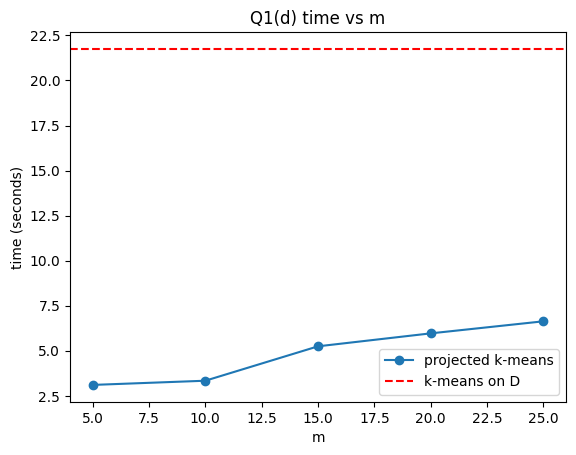

In [14]:
# Q1(d): average time of E plus k-means for each m, plot with time from (a)
avg_times = []

for m in m_list:
    times = []
    for row in results:
        if row["m"] == m:
            times.append(row["time"])
    avg_times.append(np.mean(times))

print(avg_times)

plt.plot(m_list, avg_times, marker="o", label="projected k-means")
plt.axhline(time_a, color="red", linestyle="--", label="k-means on D")
plt.xlabel("m")
plt.ylabel("time (seconds)")
plt.legend()
plt.title("Q1(d) time vs m")
plt.show()

In [15]:
# Q1(e): pick 10^4 random pairs with D_i != D_l
np.random.seed(5)

pair_i = []
pair_l = []

while len(pair_i) < 10000:
    i = np.random.randint(0, n)
    l = np.random.randint(0, n)
    if np.array_equal(D[i], D[l]) == False:
        pair_i.append(i)
        pair_l.append(l)

pair_i = np.array(pair_i)
pair_l = np.array(pair_l)

D_i = D[pair_i].astype(np.float64)
D_l = D[pair_l].astype(np.float64)
diff_D = D_i - D_l
dist_D = (diff_D * diff_D).sum(axis=1)
print(len(pair_i))

10000


In [16]:
# Q1(e)(i) and (ii): distance ratios and clustering cost ratios for each m
pair_ratios = []
cluster_ratios = []

cost_D_C = partition_cost(D, labels_D, k)

for m in m_list:
    # (i) one draw of A, ratio of squared distances for the pairs
    np.random.seed(2000 + m)
    A = np.random.normal(0, 1 / np.sqrt(m), size=(m, d))
    E_i = D_i @ A.T
    E_l = D_l @ A.T
    diff_E = E_i - E_l
    dist_E = (diff_E * diff_E).sum(axis=1)
    pair_ratios.append(dist_E / dist_D)

    # (ii) 20 draws of A, cost_E(C_D) / cost_D(C_D)
    ratios = []
    for draw in range(20):
        np.random.seed(3000 + 100 * m + draw)
        A = np.random.normal(0, 1 / np.sqrt(m), size=(m, d))
        A = A.astype(np.float32)
        E = D @ A.T
        cost_E_C = partition_cost(E, labels_D, k)
        ratios.append(cost_E_C / cost_D_C)
    cluster_ratios.append(ratios)

    print(m, np.std(pair_ratios[-1]), np.std(ratios))

5 0.4686481309058011 0.15886856239273525
10 0.3600034460959635 0.091873291510103
15 0.3686397690989831 0.09380603344580757
20 0.26855106802841655 0.08008574390780743
25 0.24674881943023355 0.05122110448633385


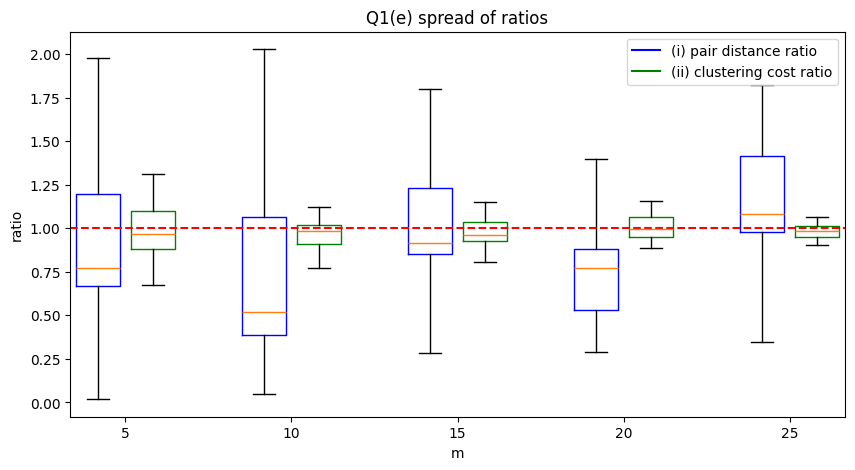

In [17]:
# Q1(e): box plots of both ratios against m in one figure
pos_i = []
pos_ii = []
tick_pos = []

for idx in range(len(m_list)):
    pos_i.append(idx * 3)
    pos_ii.append(idx * 3 + 1)
    tick_pos.append(idx * 3 + 0.5)

plt.figure(figsize=(10, 5))
plt.boxplot(pair_ratios, positions=pos_i, widths=0.8, boxprops=dict(color="blue"), showfliers=False)
plt.boxplot(cluster_ratios, positions=pos_ii, widths=0.8, boxprops=dict(color="green"), showfliers=False)
plt.xticks(tick_pos, m_list)
plt.axhline(1.0, color="red", linestyle="--")
plt.plot([], [], color="blue", label="(i) pair distance ratio")
plt.plot([], [], color="green", label="(ii) clustering cost ratio")
plt.legend()
plt.xlabel("m")
plt.ylabel("ratio")
plt.title("Q1(e) spread of ratios")
plt.show()

In [18]:
# Q2 setup: labels y and a float64 copy of D
y = (kdd.target != b"normal.").to_numpy(dtype=float)
D64 = D.astype(np.float64)

def get_loss(X, y, a):
    r = X @ a - y
    return (r * r).sum()


def count_sketch(X, y, m):
    n_rows = X.shape[0]
    h = np.random.randint(0, m, size=n_rows)
    sign = np.random.choice([-1.0, 1.0], size=n_rows)
    signed_X = X * sign.reshape(n_rows, 1)
    SX = np.zeros((m, X.shape[1]))
    Sy = np.zeros(m)
    np.add.at(SX, h, signed_X)
    np.add.at(Sy, h, sign * y)
    return SX, Sy

In [19]:
# Q2(a): full least squares, loss and time
start = time.time()
b, res, rank_D, sing = np.linalg.lstsq(D64, y, rcond=None)
end = time.time()

time_b = end - start
loss_b = get_loss(D64, y, b)

print("Loss(D, y, b) =", loss_b)
print("time =", time_b, "seconds")
print("rank(D) =", rank_D)

Loss(D, y, b) = 2949.788814857172
time = 4.878702402114868 seconds
rank(D) = 113


In [20]:
# Q2(b),(c): CountSketch runs, loss, ratio, sketched loss and time
m_list2 = [50, 100, 200, 500, 1000, 2000, 5000]
results2 = []

for m in m_list2:
    for run in range(5):
        np.random.seed(7000 + m + run)

        start = time.time()
        SD, Sy = count_sketch(D64, y, m)
        a_tilde, res, rank_s, sing = np.linalg.lstsq(SD, Sy, rcond=None)
        end = time.time()

        loss_a = get_loss(D64, y, a_tilde)
        sketch_resid = SD @ a_tilde - Sy
        sketch_loss = (sketch_resid * sketch_resid).sum()

        row = {}
        row["m"] = m
        row["run"] = run
        row["loss"] = loss_a
        row["ratio"] = loss_a / loss_b
        row["sketched_loss"] = sketch_loss
        row["time"] = end - start
        results2.append(row)

        print(m, run, row["ratio"], sketch_loss)

50 0 3.1802665275358297 7.142543851097346e-25
50 1 3.041127508774011 9.551906493650517e-25
50 2 2.498269279265189 1.1316761888029069e-23
50 3 2.520535142664377 3.5202422490839173e-23
50 4 3.4793161150831105 5.573172922197992e-24
100 0 15.227849386217787 2.3940350751647266e-24
100 1 12.795558714508973 8.025438553942513e-24
100 2 23.557680138792676 7.422970334495846e-23
100 3 7.213493934486315 1.4859646653903364e-24
100 4 16.317357146589302 6.3440604205544484e-24
200 0 2.364137612623703 1153.6609664734697
200 1 2.022302813678792 1478.188522457543
200 2 2.3570069081369054 1125.7521876689812
200 3 2.030820312556523 1489.596758480513
200 4 2.0670131206607634 1400.9260841230016
500 0 1.238979194765724 2514.3970907322705
500 1 1.312787547269491 2363.5928849370766
500 2 1.252336618979901 2495.8316954429783
500 3 1.2392964788430405 2327.5812214774405
500 4 1.2211297107658072 2190.3293138037325
1000 0 1.1272563368352442 2505.174568789216
1000 1 1.0980897488898866 2568.437163476969
1000 2 1.18101

In [21]:
# Q2(b): all runs table
all_runs2 = pd.DataFrame(results2)
print(all_runs2)

       m  run          loss      ratio  sketched_loss      time
0     50    0   9381.114631   3.180267   7.142544e-25  1.505662
1     50    1   8970.683910   3.041128   9.551906e-25  1.575461
2     50    2   7369.366776   2.498269   1.131676e-23  1.549112
3     50    3   7435.046371   2.520535   3.520242e-23  1.467535
4     50    4  10263.247760   3.479316   5.573173e-24  1.370984
5    100    0  44918.939794  15.227849   2.394035e-24  1.466531
6    100    1  37744.195976  12.795559   8.025439e-24  1.398705
7    100    2  69490.181377  23.557680   7.422970e-23  1.422398
8    100    3  21278.283724   7.213494   1.485965e-24  1.416163
9    100    4  48132.757599  16.317357   6.344060e-24  1.384160
10   200    0   6973.706687   2.364138   1.153661e+03  1.065886
11   200    1   5965.366220   2.022303   1.478189e+03  1.130853
12   200    2   6952.672614   2.357007   1.125752e+03  1.011837
13   200    3   5990.491043   2.030820   1.489597e+03  1.519593
14   200    4   6097.252183   2.067013  

In [22]:
# Q2(b): mean, min, max ratio and mean sketched loss per m
table_rows2 = []

for m in m_list2:
    ratios = []
    sketched = []
    for row in results2:
        if row["m"] == m:
            ratios.append(row["ratio"])
            sketched.append(row["sketched_loss"])

    t = {}
    t["m"] = m
    t["mean ratio"] = np.mean(ratios)
    t["min ratio"] = np.min(ratios)
    t["max ratio"] = np.max(ratios)
    t["mean sketched loss"] = np.mean(sketched)
    table_rows2.append(t)

table_b2 = pd.DataFrame(table_rows2)
print(table_b2)

      m  mean ratio  min ratio  max ratio  mean sketched loss
0    50    2.943903   2.498269   3.479316        1.075236e-23
1   100   15.022388   7.213494  23.557680        1.849584e-23
2   200    2.168256   2.022303   2.364138        1.329625e+03
3   500    1.252906   1.221130   1.312788        2.378346e+03
4  1000    1.128182   1.098090   1.181018        2.635781e+03
5  2000    1.063081   1.051460   1.068698        2.775940e+03
6  5000    1.022920   1.019681   1.027311        2.838612e+03


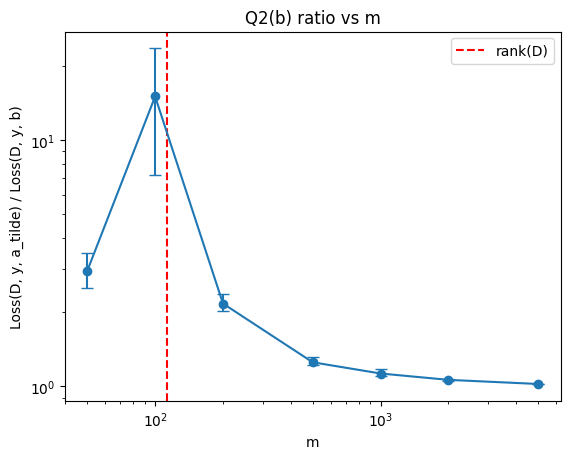

In [23]:
# Q2(b): log-log plot of mean ratio with min and max error bars
means2 = []
lower2 = []
upper2 = []

for t in table_rows2:
    means2.append(t["mean ratio"])
    lower2.append(t["mean ratio"] - t["min ratio"])
    upper2.append(t["max ratio"] - t["mean ratio"])

plt.errorbar(m_list2, means2, yerr=[lower2, upper2], marker="o", capsize=4)
plt.xscale("log")
plt.yscale("log")
plt.axvline(rank_D, color="red", linestyle="--", label="rank(D)")
plt.xlabel("m")
plt.ylabel("Loss(D, y, a_tilde) / Loss(D, y, b)")
plt.legend()
plt.title("Q2(b) ratio vs m")
plt.show()

In [24]:
# Q2(c): average time for each m compared with time of b
table_rows_c2 = []

for m in m_list2:
    times = []
    for row in results2:
        if row["m"] == m:
            times.append(row["time"])

    t = {}
    t["m"] = m
    t["mean time"] = np.mean(times)
    t["time of b"] = time_b
    table_rows_c2.append(t)

table_c2 = pd.DataFrame(table_rows_c2)
print(table_c2)

      m  mean time  time of b
0    50   1.493751   4.878702
1   100   1.417591   4.878702
2   200   1.248523   4.878702
3   500   1.368086   4.878702
4  1000   1.272838   4.878702
5  2000   1.293908   4.878702
6  5000   1.314818   4.878702


In [25]:
# Q2(d): residual v and 100 sketches for m = 50, 500, 5000
v = D64 @ b - y
v_norm = (v * v).sum()

m_list_d = [50, 500, 5000]
ratios_d = {}

for m in m_list_d:
    ratios = []
    for draw in range(100):
        np.random.seed(9000 + m + draw)
        h = np.random.randint(0, m, size=n)
        sign = np.random.choice([-1.0, 1.0], size=n)
        Sv = np.zeros(m)
        np.add.at(Sv, h, sign * v)
        ratios.append((Sv * Sv).sum() / v_norm)
    ratios_d[m] = ratios

    print(m, "mean =", np.mean(ratios), "std =", np.std(ratios))

50 mean = 0.9663343117405602 std = 0.1982645721167207
500 mean = 1.0005128055772752 std = 0.05926188542871929
5000 mean = 0.9987539645713694 std = 0.0220462571316108


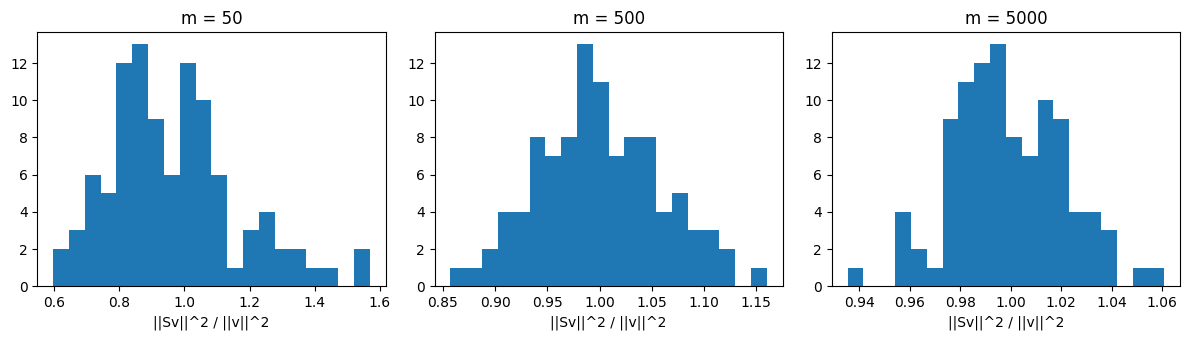

In [26]:
# Q2(d): histograms for each m
plt.figure(figsize=(12, 3.5))

plot_number = 1
for m in m_list_d:
    plt.subplot(1, 3, plot_number)
    plt.hist(ratios_d[m], bins=20)
    plt.title("m = " + str(m))
    plt.xlabel("||Sv||^2 / ||v||^2")
    plot_number = plot_number + 1

plt.tight_layout()
plt.show()

In [27]:
# Q2(e): fixed subset of 50000 rows and its exact solution b'
np.random.seed(42)
subset_index = np.random.choice(n, size=50000, replace=False)

D_sub = D64[subset_index]
y_sub = y[subset_index]

b_sub, res, rank_sub, sing = np.linalg.lstsq(D_sub, y_sub, rcond=None)
loss_sub = get_loss(D_sub, y_sub, b_sub)
print("Loss(D', y', b') =", loss_sub)

Loss(D', y', b') = 220.29057918103086


In [28]:
# Q2(e): CountSketch vs dense Gaussian sketch for m = 500
m = 500
count_times = []
count_ratios = []
dense_times = []
dense_ratios = []

for rep in range(5):
    # (i) CountSketch
    np.random.seed(11000 + rep)
    start = time.time()
    SD, Sy = count_sketch(D_sub, y_sub, m)
    end = time.time()
    count_times.append(end - start)

    a_tilde, res, rank_s, sing = np.linalg.lstsq(SD, Sy, rcond=None)
    loss_a = get_loss(D_sub, y_sub, a_tilde)
    count_ratios.append(loss_a / loss_sub)

    # (ii) dense Gaussian sketch
    np.random.seed(12000 + rep)
    start = time.time()
    S = np.random.normal(0, 1 / np.sqrt(m), size=(m, 50000))
    SD = S @ D_sub
    Sy = S @ y_sub
    end = time.time()
    dense_times.append(end - start)

    a_tilde, res, rank_s, sing = np.linalg.lstsq(SD, Sy, rcond=None)
    loss_a = get_loss(D_sub, y_sub, a_tilde)
    dense_ratios.append(loss_a / loss_sub)

print("CountSketch: time =", np.mean(count_times), "ratio =", np.mean(count_ratios))
print("Dense:       time =", np.mean(dense_times), "ratio =", np.mean(dense_ratios))

CountSketch: time = 0.12830371856689454 ratio = 1.2479443150544278
Dense:       time = 1.0925833702087402 ratio = 1.2901037063837084
